In [2]:
import tiktoken
tokenizer = tiktoken.get_encoding("cl100k_base")

import numpy as np
import matplotlib.pyplot as plt

In [3]:
import requests
import re

text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text
len(text)

179799

In [4]:
# split by punctuation
words = re.split(r'([,.:;—?_!"“()\']|--|\s)',text)
words = [item.strip() for item in words if item.strip()]

tokenCount = np.zeros((len(words),2),dtype=int)
print(tokenCount.shape)

for idx,w in enumerate(words):
  tokenCount[idx,0] = len(w) # first column is the length of the word
  tokenCount[idx,1] = len(tokenizer.encode(w)) # second column is the number of token
  
  print(f'{tokenCount[idx,0]} chars in "{w}" -> {tokenCount[idx,1]} tokens')
  

(37789, 2)
3 chars in "***" -> 1 tokens
5 chars in "START" -> 1 tokens
2 chars in "OF" -> 1 tokens
3 chars in "THE" -> 1 tokens
7 chars in "PROJECT" -> 1 tokens
9 chars in "GUTENBERG" -> 5 tokens
5 chars in "EBOOK" -> 2 tokens
2 chars in "35" -> 1 tokens
3 chars in "***" -> 1 tokens
3 chars in "The" -> 1 tokens
4 chars in "Time" -> 1 tokens
7 chars in "Machine" -> 1 tokens
2 chars in "An" -> 1 tokens
9 chars in "Invention" -> 2 tokens
2 chars in "by" -> 1 tokens
1 chars in "H" -> 1 tokens
1 chars in "." -> 1 tokens
1 chars in "G" -> 1 tokens
1 chars in "." -> 1 tokens
5 chars in "Wells" -> 2 tokens
8 chars in "CONTENTS" -> 2 tokens
1 chars in "I" -> 1 tokens
12 chars in "Introduction" -> 1 tokens
2 chars in "II" -> 1 tokens
3 chars in "The" -> 1 tokens
7 chars in "Machine" -> 1 tokens
3 chars in "III" -> 1 tokens
3 chars in "The" -> 1 tokens
4 chars in "Time" -> 1 tokens
9 chars in "Traveller" -> 3 tokens
7 chars in "Returns" -> 1 tokens
2 chars in "IV" -> 1 tokens
4 chars in "Time" ->

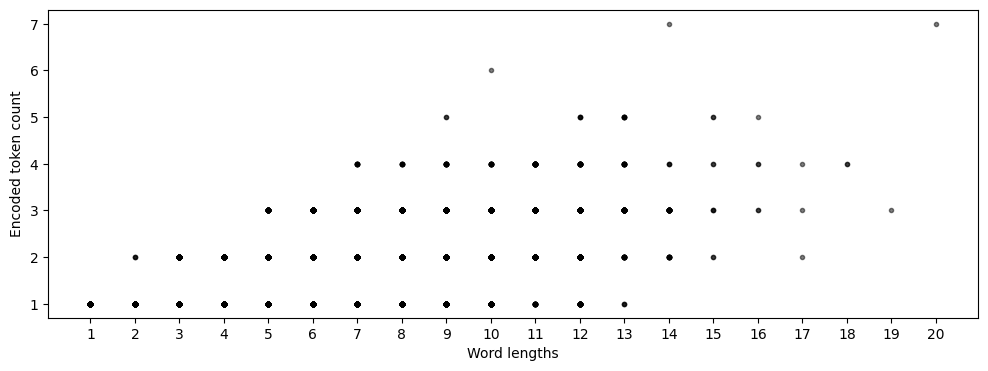

In [5]:
plt.figure(figsize=(12,4))

offsetsX = np.random.randn(len(words))/20
offsetsY = np.random.randn(len(words))/20

plt.plot(tokenCount[:,0],tokenCount[:,1],'k.',alpha=.5)
plt.gca().set(xlabel='Word lengths',ylabel='Encoded token count',xticks=np.arange(1,max(tokenCount[:,0])+1))

plt.show()

In [6]:
for idx,w in enumerate(words):
    if len(w) == 14:
        print(f'{tokenCount[idx,0]} chars in "{w}" -> {tokenCount[idx,1]} tokens')

14 chars in "intermittently" -> 3 tokens
14 chars in "mathematicians" -> 3 tokens
14 chars in "Time-Dimension" -> 3 tokens
14 chars in "Time-Dimension" -> 3 tokens
14 chars in "Time-Dimension" -> 3 tokens
14 chars in "investigations" -> 3 tokens
14 chars in "Psychologist’s" -> 3 tokens
14 chars in "potentialities" -> 2 tokens
14 chars in "incredibleness" -> 4 tokens
14 chars in "aforementioned" -> 3 tokens
14 chars in "wool-gathering" -> 4 tokens
14 chars in "interpretation" -> 2 tokens
14 chars in "Nebuchadnezzar" -> 7 tokens
14 chars in "Psychologist’s" -> 3 tokens
14 chars in "overwhelmingly" -> 3 tokens
14 chars in "disappointment" -> 2 tokens
14 chars in "interrogations" -> 3 tokens
14 chars in "conversational" -> 3 tokens
14 chars in "characteristic" -> 2 tokens
14 chars in "specialisation" -> 2 tokens
14 chars in "interpretation" -> 2 tokens
14 chars in "interpretation" -> 2 tokens
14 chars in "self-restraint" -> 3 tokens
14 chars in "expostulations" -> 3 tokens
14 chars in "ill

In [7]:
wordsWith14Chars = set(np.where(tokenCount[:,0] == 14)[0])

for idx in wordsWith14Chars:
    this_decode = [tokenizer.decode([t]) for t in tokenizer.encode(words[idx])]
    print(f'{words[idx]} comprises of {this_decode}')

interpretation comprises of ['interpret', 'ation']
aforementioned comprises of ['a', 'fore', 'mentioned']
constellations comprises of ['const', 'ell', 'ations']
specialisation comprises of ['special', 'isation']
Time-Dimension comprises of ['Time', '-D', 'imension']
Psychologist’s comprises of ['Psych', 'ologist', '’s']
conversational comprises of ['con', 'vers', 'ational']
north-eastward comprises of ['north', '-east', 'ward']
Undergrounders comprises of ['Under', 'ground', 'ers']
mathematicians comprises of ['math', 'ematic', 'ians']
interpretation comprises of ['interpret', 'ation']
discriminating comprises of ['disc', 'rim', 'inating']
mountaineering comprises of ['mount', 'aine', 'ering']
ill-controlled comprises of ['ill', '-controlled']
Psychologist’s comprises of ['Psych', 'ologist', '’s']
North-eastward comprises of ['North', '-east', 'ward']
interrogations comprises of ['inter', 'rog', 'ations']
self-deception comprises of ['self', '-de', 'ception']
differentiated comprises o

# Token efficiency

it can be calculated by calculating the number of character divided be the number of tokens


for w in words:
    print(f'{len(w)} chars in "{w}" -> {len(tokenizer.encode(w))} tokens {w}')
    # token efficiency calculation
    efficiency = len(tokenizer.encode(w)) / len(w) if len(w) > 0 else 0
    print(f'  Token efficiency: {efficiency:.2f}')
tokenCount.shape

In [8]:
import pandas as pd
df = pd.DataFrame(tokenCount, columns=['word_length', 'token_count'])
df.head() # i wanted to use pandas to under the content of the data and to see if there are any patterns in the data. I also wanted to use pandas to see if there are any correlations between the word length and the token count.

,word_length,token_count
0,3,1
1,5,1
2,2,1
3,3,1
4,7,1


In [9]:
# there for word efficiency is basically

efficiency = tokenCount[:,0] / tokenCount[:,1]
efficiency

array([3. , 5. , 2. , ..., 2.5, 2. , 3. ], shape=(37789,))

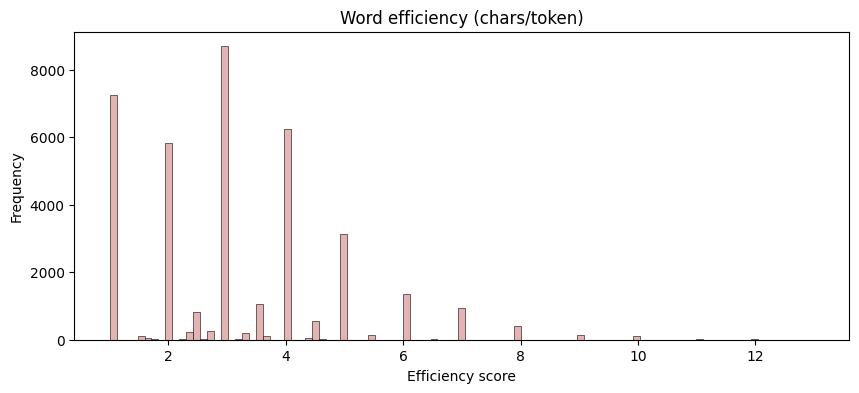

In [10]:
# show a historgram
plt.figure(figsize=(10,4))
plt.hist(efficiency,color=[.9,.7,.7],edgecolor='k',linewidth=.4,bins='fd')
plt.gca().set(xlabel='Efficiency score',ylabel='Frequency',title='Word efficiency (chars/token)')
plt.show()

In [11]:
# find the most and least efficiently tokenized words
max_efficiency = np.max(efficiency)
min_efficiency = np.min(efficiency)

# find all the words with those efficiency values
most_efficient_words = np.where(efficiency==max_efficiency)[0]
least_efficient_words = np.where(efficiency==min_efficiency)[0]

# find and print the unique words with max-efficiency score
most_efficient_words = list(set([ words[i] for i in most_efficient_words ]))

print('MOST EFFICIENT WORDS:')
for w in most_efficient_words:
  print(f'"{w}" has {max_efficiency} characters per token')

MOST EFFICIENT WORDS:
"advertisement" has 13.0 characters per token
"communication" has 13.0 characters per token


In [12]:
tmTokens = tokenizer.encode(text)

In [13]:
# repeat for min-efficiency score
print('\n\nLEAST EFFICIENT WORDS:')
for w in list(set([ words[i] for i in least_efficient_words ])):
  print(f'"{w}" has {min_efficiency:.2f} characters per token')



LEAST EFFICIENT WORDS:
"]" has 1.00 characters per token
"”" has 1.00 characters per token
")" has 1.00 characters per token
"," has 1.00 characters per token
"…" has 1.00 characters per token
"?" has 1.00 characters per token
"“" has 1.00 characters per token
"G" has 1.00 characters per token
":" has 1.00 characters per token
"!" has 1.00 characters per token
"A" has 1.00 characters per token
"’" has 1.00 characters per token
"." has 1.00 characters per token
"a" has 1.00 characters per token
"V" has 1.00 characters per token
"(" has 1.00 characters per token
"‘I" has 1.00 characters per token
";" has 1.00 characters per token
"_" has 1.00 characters per token
"H" has 1.00 characters per token
"X" has 1.00 characters per token
"—" has 1.00 characters per token
"I" has 1.00 characters per token
"XV" has 1.00 characters per token
"D" has 1.00 characters per token


In [14]:
# unique set of words as we've split them up
uniqueWords = set(words)
print(f'There are {len(uniqueWords)} unique words in The Time Machine according to our split.')

There are 5006 unique words in The Time Machine according to our split.


In [15]:
# random token
token_idx = np.random.randint(0,tokenizer.n_vocab//10)

# non-random tokens to try
# token_idx = 1879#,5030#,716

# find the words (from our split) in The Time Machine that contain that token
words_with_token = [w for w in uniqueWords if token_idx in tokenizer.encode(w)]

# find the context (from the full encoding) surrounding each token appearance
seqs_with_token = np.array(tmTokens)==token_idx

# print the token
print(f'Token {token_idx} is "{tokenizer.decode([token_idx])}"\n\n')

# its occurance in our manually split words
# its occurances in the GPT encoding
print(f'\n\n*** From encoding the full text: This token appears {sum(seqs_with_token)} times')
for s in np.where(seqs_with_token)[0]:
  print(f'{tokenizer.decode(tmTokens[s-5:s+6])}\n-----------')

Token 7087 is "-label"




*** From encoding the full text: This token appears 0 times


# how many times a unique token appears in the bag of words

In [16]:
uniqueWords = set(words)

In [17]:
for w in uniqueWords:
    total = 0
    for w2 in words:
        if w == w2:
            total += 1
    print(f'{w} appears {total} times in the text')

with appears 209 times in the text
arm-rests appears 1 times in the text
woman appears 3 times in the text
memory appears 10 times in the text
perceived appears 5 times in the text
situation appears 1 times in the text
colossal appears 4 times in the text
verbatim appears 1 times in the text
Parts appears 1 times in the text
order appears 4 times in the text
stood appears 24 times in the text
floated appears 1 times in the text
others appears 12 times in the text
humanity appears 8 times in the text
big appears 17 times in the text
No appears 9 times in the text
holding appears 5 times in the text
deep appears 4 times in the text
sleight-of-hand appears 1 times in the text
connect appears 1 times in the text
deeply appears 1 times in the text
grimly appears 1 times in the text
spellbound appears 1 times in the text
champagne appears 2 times in the text
fly appears 1 times in the text
showing appears 1 times in the text
print appears 1 times in the text
aloud appears 3 times in the text

# the for loop above is slow, using counter would be relatively faster as counter would do it in one go

_______________

In [18]:
from collections import Counter

word_counts = Counter(words)
#word_counts

for w, total in word_counts.items():
    print(f'{w} appears {total} times in the text')

*** appears 4 times in the text
START appears 1 times in the text
OF appears 2 times in the text
THE appears 2 times in the text
PROJECT appears 2 times in the text
GUTENBERG appears 2 times in the text
EBOOK appears 2 times in the text
35 appears 2 times in the text
The appears 219 times in the text
Time appears 123 times in the text
Machine appears 41 times in the text
An appears 3 times in the text
Invention appears 1 times in the text
by appears 99 times in the text
H appears 1 times in the text
. appears 1804 times in the text
G appears 1 times in the text
Wells appears 1 times in the text
CONTENTS appears 1 times in the text
I appears 1251 times in the text
Introduction appears 2 times in the text
II appears 2 times in the text
III appears 2 times in the text
Traveller appears 55 times in the text
Returns appears 2 times in the text
IV appears 2 times in the text
Travelling appears 2 times in the text
V appears 2 times in the text
In appears 37 times in the text
the appears 2065 

# count the number of tokens in each word

In [19]:
for w in uniqueWords:
    tokens = tokenizer.encode(w)
    print(f'{w} has {len(list(set(tokens)))} unique tokens')

with has 1 unique tokens
arm-rests has 3 unique tokens
woman has 1 unique tokens
memory has 1 unique tokens
perceived has 2 unique tokens
situation has 2 unique tokens
colossal has 2 unique tokens
verbatim has 1 unique tokens
Parts has 1 unique tokens
order has 1 unique tokens
stood has 1 unique tokens
floated has 2 unique tokens
others has 1 unique tokens
humanity has 2 unique tokens
big has 1 unique tokens
No has 1 unique tokens
holding has 1 unique tokens
deep has 1 unique tokens
sleight-of-hand has 5 unique tokens
connect has 1 unique tokens
deeply has 2 unique tokens
grimly has 2 unique tokens
spellbound has 2 unique tokens
champagne has 3 unique tokens
fly has 1 unique tokens
showing has 2 unique tokens
print has 1 unique tokens
aloud has 2 unique tokens
fifteen has 3 unique tokens
relief has 2 unique tokens
self-devotion has 3 unique tokens
sends has 2 unique tokens
Learn has 1 unique tokens
steatite has 3 unique tokens
fullness has 2 unique tokens
complex has 1 unique tokens
to

# doin same thing right here in a different way

In [20]:
# the unique words, as a list instead of a set (for indexing)
uniqueWords = list(uniqueWords)

# initialize results vectors
wordFreq = np.zeros(len(uniqueWords),dtype=int)
numTokens = np.zeros(len(uniqueWords),dtype=int)

# loop through all unique words
for i,uword in enumerate(uniqueWords):

  # count the number of times that word appears
  wordFreq[i] = words.count(uword)

  # count the number of tokens in that word
  numTokens[i] = len(tokenizer.encode(uword))

In [21]:
wordFreq.shape 

(5006,)

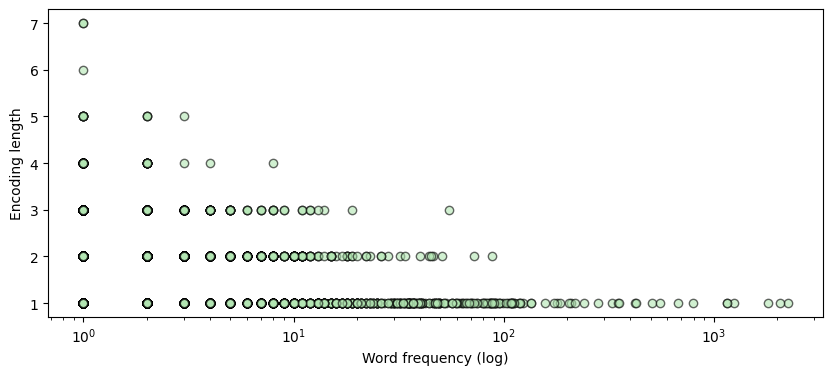

In [22]:
plt.figure(figsize=(10,4))
plt.plot(wordFreq,numTokens,'ko',markerfacecolor=[.7,.9,.7],alpha=.6)
plt.gca().set(xlabel='Word frequency (log)',ylabel='Encoding length',xscale='log')
plt.show()

In [23]:
wordFreqidx = np.argsort(wordFreq)[::-1]
for i in wordFreqidx[:20]:
  print(f'{wordFreq[i]:>5,} appearances of "{uniqueWords[i]}"')

2,250 appearances of ","
2,065 appearances of "the"
1,804 appearances of "."
1,251 appearances of "I"
1,156 appearances of "of"
1,150 appearances of "and"
  795 appearances of "a"
  672 appearances of "to"
  552 appearances of "was"
  509 appearances of "in"
  426 appearances of "my"
  421 appearances of "that"
  352 appearances of "“"
  350 appearances of "had"
  329 appearances of "it"
  281 appearances of "me"
  240 appearances of "as"
  219 appearances of "The"
  209 appearances of "with"
  205 appearances of "at"


# pick three random tokens and return them or join them with white spaces

In [30]:
rand_tokens = np.random.choice(words, size=3, replace=False)
tokens = []
for w in rand_tokens:
    token = tokenizer.encode(w)
    tokens.extend(token)
print(tokenizer.decode(tokens))

infasterThis


In [35]:
nTokens = 3

# choose some random tokens
randtokens = np.random.choice(range(tokenizer.n_vocab),nTokens)

# print the individual tokens
for t in randtokens:
  print(f'Token {t} is "{tokenizer.decode([t])}"')

# fake word without whitespace
fakeword = re.sub(r'\s+','',tokenizer.decode(randtokens))

print(f'\nThe fake word is "{fakeword}"')

Token 90268 is " aun"
Token 91977 is " signalling"
Token 77108 is " cuatro"

The fake word is "aunsignallingcuatro"
